# 03 · Training: Model A (clean) vs Model B (noise-augmented)
Both models start from the self-supervised **`facebook/wav2vec2-base`**: 95M parameters, no CTC head, no fine-tuning on transcripts. We add a fresh 32-way character CTC head and fine-tune on LibriSpeech **train-clean-100** with an **identical recipe**. The only difference is on-the-fly noise augmentation for B, so any gap between them is due to the noise training (objective O2).

Code: `scripts/train.py`. Configs: `configs/train_{A_clean,B_noisy}.yaml`. Checkpoints and curves: `experiments/runs/`.

**Recipe:**
- AdamW, peak learning rate 5e-5, 8% warm-up then linear decay.
- 36k steps of about 640 s of audio each (about 64 epochs).
- bf16 precision, frozen convolutional feature encoder.
- SpecAugment-style time masking 0.4 and feature masking 0.1, LayerDrop 0.1.
- The CTC loss is computed with the *true* (unpadded) frame counts.
- The checkpoint is selected by the average dev WER over clean and held-out-MUSAN noisy audio.

*Re-run this notebook at any time to refresh the curves while training is in progress.*

In [1]:
import sys, json, warnings
from pathlib import Path
cwd = Path.cwd()
REPO = next(p for p in (cwd, *cwd.parents) if (p / "src" / "group9_ds_ai_lab").is_dir())
sys.path.insert(0, str(REPO / "src"))
from group9_ds_ai_lab.utils.paths import *   # noqa  (all project paths)
setup_env()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown, Audio
from group9_ds_ai_lab.utils.plotstyle import apply_style, SERIES, INK, INK2, GRID, SURF, MODEL_COLOR, MODEL_LABEL, NOISE_COLOR
apply_style(); warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)
print("repo:", REPO)

repo: <repo root>


In [2]:
import yaml
cfgs = {n: yaml.safe_load(open(CONFIGS / f"train_{n}.yaml")) for n in ("A_clean", "B_noisy")}
display(pd.DataFrame(cfgs).fillna("-"))

,A_clean,B_noisy
name,A_clean,B_noisy
init_model,facebook/wav2vec2-base,facebook/wav2vec2-base
augment,False,True
max_steps,36000,36000
lr,0.000,0.000
warmup_ratio,0.080,0.080
max_batch_seconds,640,640
eval_every,2000,2000
save_every,2000,2000
seed,42,42


In [3]:
logs = {}
for n in ("A_clean", "B_noisy"):
    t, e = RUNS / n / "train_log.csv", RUNS / n / "eval_log.csv"
    logs[n] = (pd.read_csv(t) if t.exists() else None, pd.read_csv(e) if e.exists() else None)
    tl = logs[n][0]
    print(f"{n}: " + (f"step {int(tl.step.max()):,} / {cfgs[n]['max_steps']:,}" if tl is not None else "not started"))

A_clean: step 36,000 / 36,000
B_noisy: step 36,000 / 36,000


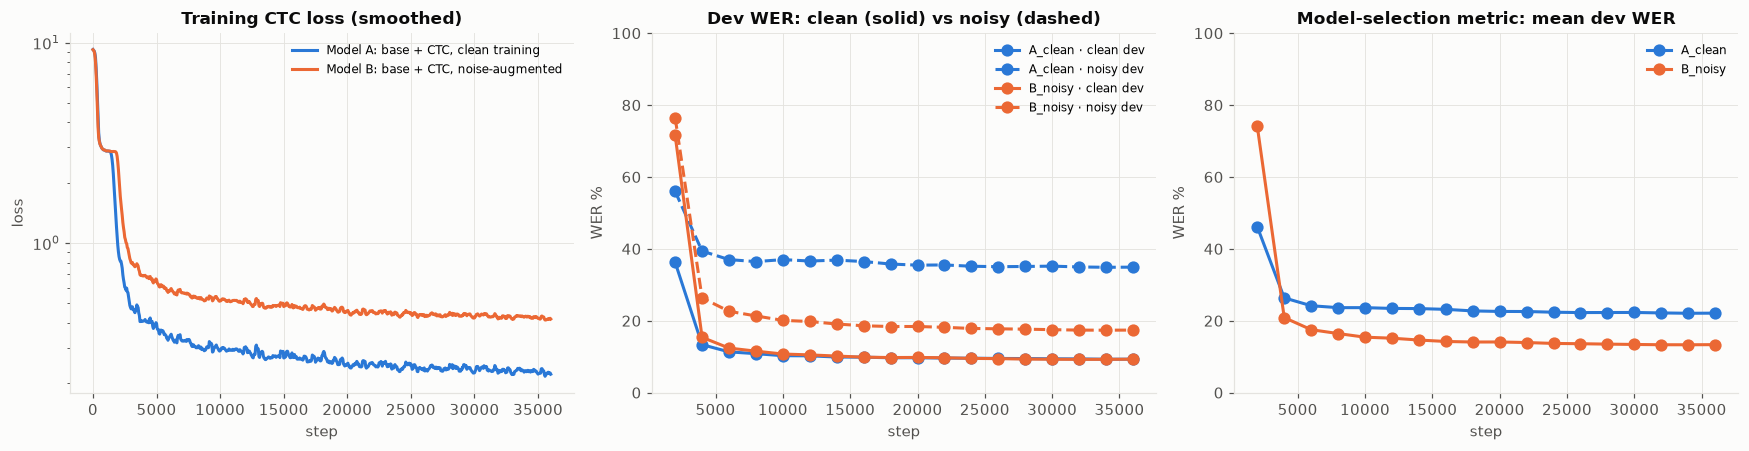

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for n, (tl, el) in logs.items():
    c = MODEL_COLOR[n]
    if tl is not None:
        axes[0].plot(tl.step, tl.loss.rolling(5, min_periods=1).mean(), color=c, label=MODEL_LABEL[n])
    if el is not None:
        axes[1].plot(el.step, el.wer_clean * 100, color=c, marker="o", label=f"{n} · clean dev")
        axes[1].plot(el.step, el.wer_noisy * 100, color=c, marker="o", ls="--", label=f"{n} · noisy dev")
        axes[2].plot(el.step, el.wer_avg * 100, color=c, marker="o", label=n)
axes[0].set(title="Training CTC loss (smoothed)", xlabel="step", ylabel="loss", yscale="log"); axes[0].legend(fontsize=8)
axes[1].set(title="Dev WER: clean (solid) vs noisy (dashed)", xlabel="step", ylabel="WER %", ylim=(0, 100)); axes[1].legend(fontsize=8)
axes[2].set(title="Model-selection metric: mean dev WER", xlabel="step", ylabel="WER %", ylim=(0, 100)); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [5]:
for n, (tl, el) in logs.items():
    if el is not None:
        display(Markdown(f"**{n}**: dev evaluations"))
        display(el[["step", "wer_clean", "wer_noisy", "wer_avg", "cer_clean", "cer_noisy", "empty_hyp_frac"]].tail(20))
        best = el.loc[el.wer_avg.idxmin()]
        print(f"best step {int(best.step)}: clean {best.wer_clean*100:.2f}%  noisy {best.wer_noisy*100:.2f}%   example:\n  REF {best.example_ref}\n  HYP {best.example_hyp}")

**A_clean**: dev evaluations

,step,wer_clean,wer_noisy,wer_avg,cer_clean,cer_noisy,empty_hyp_frac
0,2000,0.363,0.560,0.461,0.107,0.283,0.003
1,4000,0.133,0.394,0.264,0.043,0.206,0.001
2,6000,0.113,0.370,0.242,0.037,0.196,0.000
3,8000,0.108,0.364,0.236,0.036,0.191,0.000
4,10000,0.103,0.370,0.236,0.035,0.197,0.000
5,12000,0.102,0.366,0.234,0.035,0.199,0.000
6,14000,0.099,0.369,0.234,0.034,0.203,0.000
7,16000,0.099,0.365,0.232,0.034,0.195,0.000
8,18000,0.097,0.358,0.227,0.034,0.192,0.001
9,20000,0.097,0.355,0.226,0.034,0.191,0.000


best step 34000: clean 9.29%  noisy 34.87%   example:
  REF HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED
  HYP HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKEY THE BOYS ROARED


**B_noisy**: dev evaluations

,step,wer_clean,wer_noisy,wer_avg,cer_clean,cer_noisy,empty_hyp_frac
0,2000,0.716,0.765,0.741,0.312,0.371,0.001
1,4000,0.154,0.264,0.209,0.049,0.107,0.000
2,6000,0.124,0.226,0.175,0.040,0.094,0.000
3,8000,0.115,0.213,0.164,0.038,0.090,0.000
4,10000,0.107,0.201,0.154,0.036,0.085,0.000
5,12000,0.105,0.198,0.151,0.036,0.084,0.000
6,14000,0.102,0.191,0.146,0.035,0.081,0.000
7,16000,0.099,0.186,0.142,0.034,0.079,0.000
8,18000,0.098,0.184,0.141,0.034,0.078,0.000
9,20000,0.098,0.184,0.141,0.034,0.078,0.000


best step 34000: clean 9.26%  noisy 17.37%   example:
  REF HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED
  HYP HAT TOO CLOSE TO BE I COULDN'T GET IT EXPLAINED CUNKEY THE BOY'S RARED


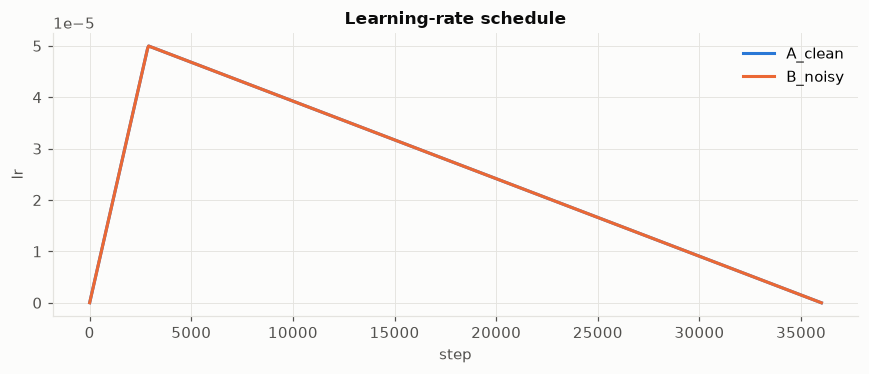

A_clean: 0.38 s/step, 1584 s of audio per s, peak GPU mem 10.9 GB
B_noisy: 0.38 s/step, 1581 s of audio per s, peak GPU mem 10.9 GB


In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for n, (tl, el) in logs.items():
    if tl is not None:
        ax.plot(tl.step, tl.lr, color=MODEL_COLOR[n], label=n)
ax.set(title="Learning-rate schedule", xlabel="step", ylabel="lr"); ax.legend(); plt.tight_layout(); plt.show()
for n, (tl, el) in logs.items():
    if tl is not None and len(tl) > 3:
        r = tl.iloc[2:]
        print(f"{n}: {r.sec_per_step.median():.2f} s/step, {r.audio_sec_per_sec.median():.0f} s of audio per s, peak GPU mem {tl.max_mem_gb.max():.1f} GB")